# 1. Import thư viện và nạp dữ liệu vào notebook
+ Nạp tập dữ liệu Bệnh tiểu đường ở người da đỏ Pima.
+ do data trong link https://www.kaggle.com/code/vincentlugat/pima-indians-diabetes-eda-prediction-0-906 nằm trong trạng thái riêng tư không thể lấy được
+ nên tôi quyết định lấy data từ link: https://www.kaggle.com/datasets/mragpavank/diabetes

In [36]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
# Nếu đã tải file về thư mục data/
diabetes_data = pd.read_csv("data/diabetes.csv")

# 2. Kiểm tra thông tin tập dữ liệu
+ Xem 5 dòng đầu tiên của tập dữ liệu.
+ Kiểm tra kiểu dữ liệu các cột.
+ Kiểm tra kích thước (số dòng, số cột) ban đầu.

In [37]:
diabetes_data.head(5)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


**Phát Hiện:** Trong cột skinThickness, Insulin có dòng bằng 0, điều vô lý trong thực tế.

In [38]:
diabetes_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [39]:
diabetes_data.shape

(768, 9)

# 3. Làm sạch dữ liệu (Data Cleaning)
+ Lọc bỏ các dòng bị trùng lặp hoàn toàn để đảm bảo tính chính xác cho các phép tính thống kê.
+ Kiểm tra số lượng giá trị thiếu (NaN).

### 3.1. Kiểm tra số dòng bị trùng lặp và loại bỏ

In [40]:
num_duplicates = diabetes_data.duplicated().sum()
print(f"Số dòng bị trùng lặp: {num_duplicates}")

Số dòng bị trùng lặp: 0



### 3.2. Kiểm tra số lượng giá trị thiếu (NaN) trên từng cột

In [41]:
diabetes_data.isnull().sum()


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

**Phát Hiện:** bài này có các giá trị bị thiếu (NaN) trong các cột nhưng dưới dạng là số 0.

# 4. Biến đổi dữ liệu (Data Transformation)
+ Tạo cột Outcome_label để chuyển đổi biến mục tiêu từ số (0, 1) sang dạng chữ ('No', 'Yes') giúp giao diện hiển thị trực quan hơn khi phân nhóm.

In [42]:
diabetes_data['Outcome_label'] = diabetes_data['Outcome'].replace(
    [0, 1], 
    ['No', 'Yes']
)

# Xem thử kết quả phân nhóm
diabetes_data[['Outcome', 'Outcome_label']].head(10)

,Outcome,Outcome_label
0,1,Yes
1,0,No
2,1,Yes
3,0,No
4,1,Yes
5,0,No
6,1,Yes
7,0,No
8,1,Yes
9,1,Yes


# 5. Tính toán các chỉ số thống kê mô tả (Descriptive Statistics)
+ Thực hiện tính toán trên tập dữ liệu đã làm sạch.
+ Chọn cột Glucose (Nồng độ đường huyết) làm biến phân tích đại diện do đây là chỉ số tương quan mạnh nhất với khả năng mắc bệnh tiểu đường.

In [43]:
# Tính toán các chỉ số
data_mean = np.mean(diabetes_data["Glucose"])
data_median = np.median(diabetes_data["Glucose"])
data_mode = stats.mode(diabetes_data["Glucose"])
data_variance = np.var(diabetes_data["Glucose"])
data_sd = np.std(diabetes_data["Glucose"])
data_max = np.max(diabetes_data["Glucose"])
data_min = np.min(diabetes_data["Glucose"])
data_percentile = np.percentile(diabetes_data["Glucose"], 60)
data_quartile = np.quantile(diabetes_data["Glucose"], 0.75)
data_IQR = stats.iqr(diabetes_data["Glucose"])

# In nguyên bản kết quả không dùng định dạng làm tròn :.2f
print(f"Mean: {data_mean}")
print(f"Median: {data_median}")
print(f"Mode: {np.ravel(data_mode.mode)[0]}")
print(f"Variance: {data_variance}")
print(f"Standard Deviation: {data_sd}")
print(f"Min: {data_min} | Max: {data_max}")
print(f"Range: {data_max - data_min}")
print(f"60th Percentile: {data_percentile}")
print(f"Q3 (75th Percentile): {data_quartile}")
print(f"IQR: {data_IQR}")

Mean: 120.89453125
Median: 117.0
Mode: 99
Variance: 1020.9172617594401
Standard Deviation: 31.95179590820272
Min: 0 | Max: 199
Range: 199
60th Percentile: 125.0
Q3 (75th Percentile): 140.25
IQR: 41.25


## 6. Trực quan hóa dữ liệu với thư viện Seaborn

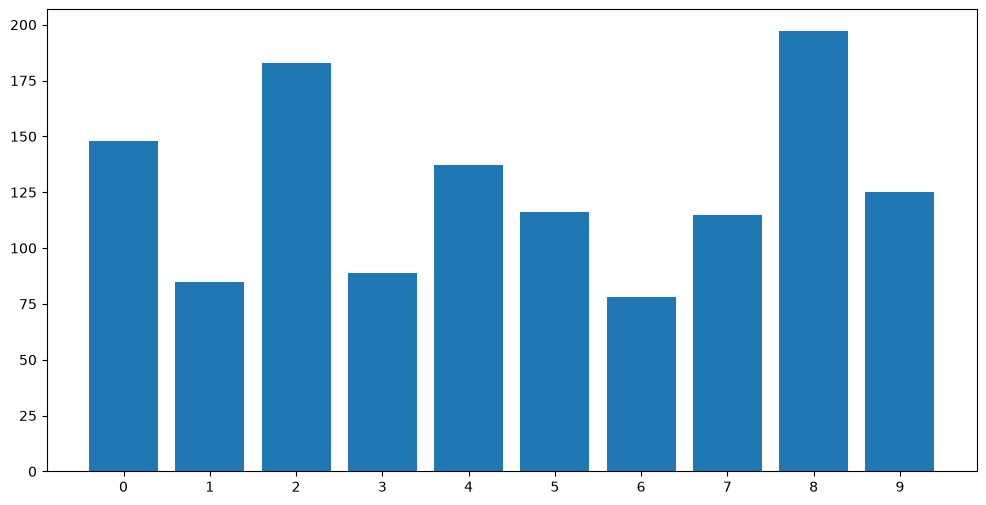

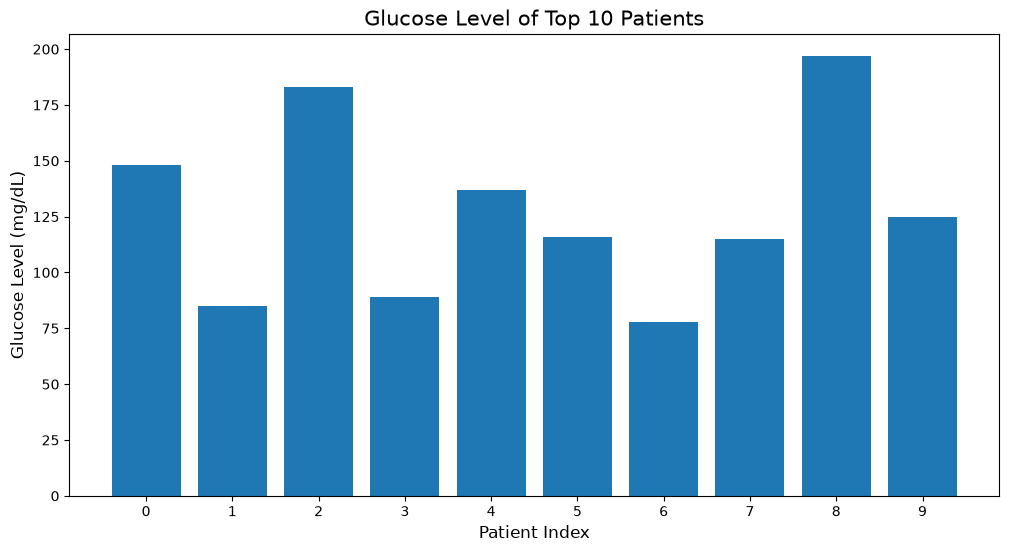

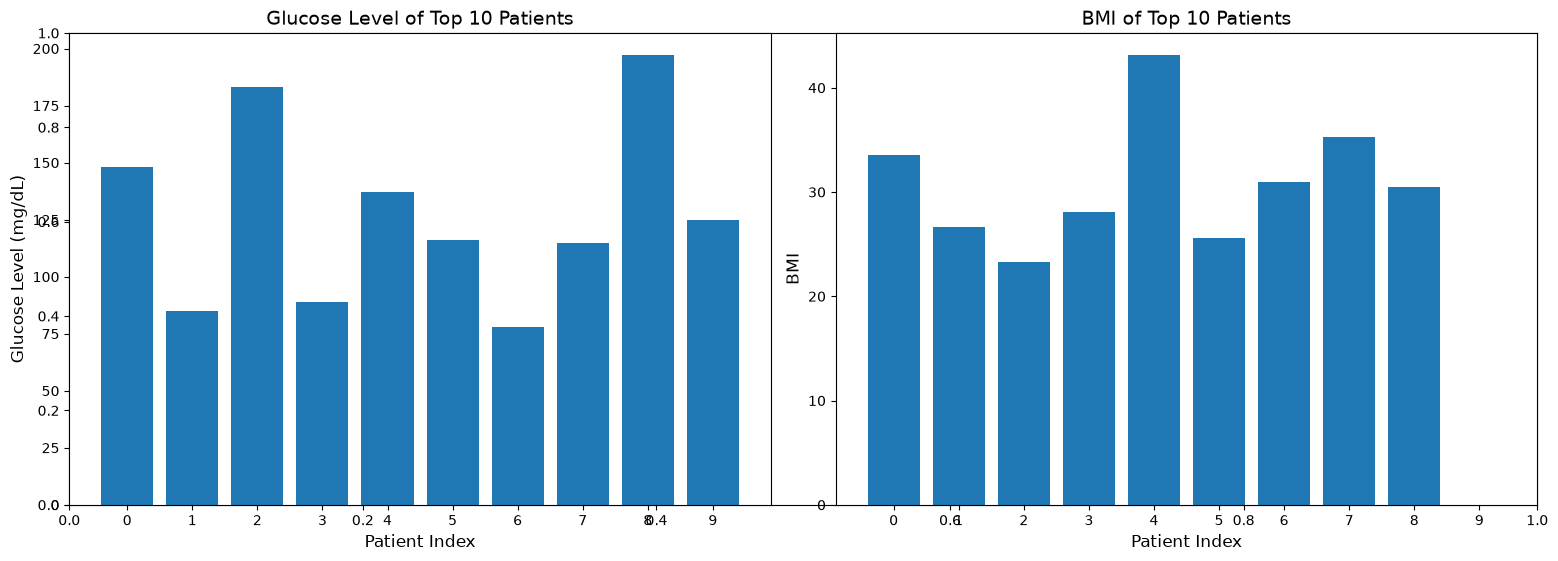

In [45]:
# Reset giao diện phông chữ về chuẩn ban đầu
sns.reset_orig()

data_top10 = diabetes_data[0:10]

x = data_top10.index.astype(str)  # Lấy chỉ số ID bệnh nhân (0 đến 9)
y = data_top10["Glucose"]
y1 = data_top10["BMI"]

# --- Case 1: Basic ---
plt.figure(figsize=(12, 6))
plt.bar(x, y)
plt.ticklabel_format(style="plain", axis="y")
plt.show()

# --- Case 2: Advanced 1 ---
plt.figure(figsize=(12, 6))
plt.bar(x, y)
plt.ticklabel_format(style="plain", axis="y")
plt.title("Glucose Level of Top 10 Patients", fontsize=15)
plt.xlabel("Patient Index", fontsize=12)
plt.xticks(fontsize=10)
plt.ylabel("Glucose Level (mg/dL)", fontsize=12)
plt.yticks(fontsize=10)
plt.show()

# --- Case 3: Advanced 2 ---
fig, ax = plt.subplots(figsize=(16, 6))

plt.subplot(1, 2, 1)
plt.bar(x, y)
plt.ticklabel_format(style="plain", axis="y")
plt.xticks(fontsize=10, rotation=0)
plt.xlabel("Patient Index", fontsize=12)
plt.ylabel("Glucose Level (mg/dL)", fontsize=12)
plt.yticks(fontsize=10)
plt.title("Glucose Level of Top 10 Patients", fontsize=14)

plt.subplot(1, 2, 2)
plt.bar(x, y1)
plt.xticks(fontsize=10, rotation=0)
plt.xlabel("Patient Index", fontsize=12)
plt.ylabel("BMI", fontsize=12)
plt.yticks(fontsize=10)
plt.title("BMI of Top 10 Patients", fontsize=14)

plt.tight_layout()
plt.show()